# 01. ISBI 2015 Longitudinal MS Lesion Dataset: Exploration, Zero-Leakage Splits & Inter-Rater Baseline

This notebook explores the **ISBI 2015 Longitudinal Multiple Sclerosis Lesion Segmentation Dataset** stored in `/content/drive/MyDrive/masters/data`:
1. **Cohort Discovery:** Scans all 19 subjects (5 labeled training patients with 21 visits and dual expert masks `mask1`/`mask2`, plus 14 unlabeled test patients with 61 visits across `FLAIR`, `MPRAGE`, `T2-w`, and `PD-w`).
2. **Strict Patient-Level LOPO Splits:** Verifies zero data leakage between the SimCLR pretraining pool (18 patients), supervised training pool (4 patients), and held-out validation patient (1 patient).
3. **Human Inter-Rater Ceiling:** Computes the Dice similarity agreement between Expert Rater 1 (`mask1`) and Expert Rater 2 (`mask2`).
4. **Longitudinal Visualization:** Plots 4-modality orthoslices, patient lesion load trajectories $V(t)$ over time, and 3-state lesion evolution maps (**Stable**, **New/Enlarging**, **Shrinking**).

In [1]:
!git clone https://github.com/edupras/simclr-ms-mri.git

Cloning into 'simclr-ms-mri'...
remote: Enumerating objects: 41, done.
remote: Counting objects: 100% (41/41), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 41 (delta 4), reused 34 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (41/41), 332.66 KiB | 33.26 MiB/s, done.
Resolving deltas: 100% (4/4), done.


In [2]:
# 1. Mount Google Drive & Configure Environment on Colab Pro (A100)
import os
import sys
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Install required medical imaging packages if running in fresh Colab runtime
if IN_COLAB:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'monai>=1.3.0', 'nibabel>=5.0.0', 'pyyaml', 'tqdm'])

# Add repository root to sys.path
REPO_CANDIDATES = [
    Path('/content/drive/MyDrive/masters/simclr-ms-mri'),
    Path('/content/simclr-ms-mri'),
    Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd(),
]
for candidate in REPO_CANDIDATES:
    if (candidate / 'src').exists():
        PROJECT_ROOT = candidate.resolve()
        if str(PROJECT_ROOT) not in sys.path:
            sys.path.insert(0, str(PROJECT_ROOT))
        break

import torch
print(f'Project Root: {PROJECT_ROOT}')
print(f'PyTorch: {torch.__version__} | CUDA Available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU Device: {torch.cuda.get_device_name(0)} | BF16 Supported: {torch.cuda.is_bf16_supported()}')

Mounted at /content/drive
Project Root: /content/simclr-ms-mri
PyTorch: 2.14.1+cu130 | CUDA Available: True
GPU Device: NVIDIA L4 | BF16 Supported: True


In [3]:
# 2. Load Configuration & Discover All ISBI 2015 Longitudinal Visits
from src.utils.config import load_config, set_deterministic_seed
from src.data.isbi_dataset import discover_isbi2015_visits, build_longitudinal_pairs, get_lopo_fold_splits

cfg = load_config(PROJECT_ROOT / 'configs' / 'default.yaml')
set_deterministic_seed(cfg['project']['seed'])

DATA_ROOT = Path(cfg['data']['root_dir'])
patient_visits = discover_isbi2015_visits(DATA_ROOT, modalities=cfg['data']['modalities'])
patient_pairs = build_longitudinal_pairs(patient_visits, max_time_gap_norm=cfg['data']['max_time_gap_norm'])

total_visits = sum(len(v) for v in patient_visits.values())
total_pairs = sum(len(p) for p in patient_pairs.values())
print(f'Discovered {len(patient_visits)} patients | {total_visits} total MRI sessions | {total_pairs} ordered longitudinal visit pairs\n')

print(f"{'Patient ID':<14} | {'Subset':<10} | {'# Visits':<9} | {'# Forward Pairs':<15}")
print('-' * 56)
for pid, visits in sorted(patient_visits.items()):
    subset = 'Labeled' if visits[0].is_labeled else 'Unlabeled'
    n_pairs = len(patient_pairs.get(pid, []))
    print(f'{pid:<14} | {subset:<10} | {len(visits):<9} | {n_pairs:<15}')

Discovered 19 patients | 82 total MRI sessions | 139 ordered longitudinal visit pairs

Patient ID     | Subset     | # Visits  | # Forward Pairs
--------------------------------------------------------
test01         | Unlabeled  | 4         | 6              
test02         | Unlabeled  | 5         | 10             
test03         | Unlabeled  | 4         | 6              
test04         | Unlabeled  | 4         | 6              
test05         | Unlabeled  | 4         | 6              
test06         | Unlabeled  | 4         | 6              
test07         | Unlabeled  | 4         | 6              
test08         | Unlabeled  | 4         | 6              
test09         | Unlabeled  | 4         | 6              
test10         | Unlabeled  | 6         | 15             
test11         | Unlabeled  | 5         | 10             
test12         | Unlabeled  | 4         | 6              
test13         | Unlabeled  | 4         | 6              
test14         | Unlabeled  | 5         | 10

In [4]:
# 3. Verify Strict Zero-Leakage 5-Fold Leave-One-Patient-Out (LOPO) Splits
for fold_idx in range(5):
    split = get_lopo_fold_splits(patient_visits, fold_idx=fold_idx)
    split.verify_zero_leakage()
    print(
        f'Fold {fold_idx}: Held-Out Val = {split.val_patient_id} ({len(split.seg_val_pairs)} pairs) | '
        f'Seg Train = {len(split.train_labeled_patient_ids)} patients ({len(split.seg_train_pairs)} pairs) | '
        f'SimCLR Pool = {len(split.simclr_patient_ids)} patients ({len(split.simclr_pairs)} pairs)'
    )
print('\nAll 5 LOPO folds passed strict zero-leakage verification!')

Fold 0: Held-Out Val = training01 (6 pairs) | Seg Train = 4 patients (28 pairs) | SimCLR Pool = 18 patients (133 pairs)
Fold 1: Held-Out Val = training02 (6 pairs) | Seg Train = 4 patients (28 pairs) | SimCLR Pool = 18 patients (133 pairs)
Fold 2: Held-Out Val = training03 (10 pairs) | Seg Train = 4 patients (24 pairs) | SimCLR Pool = 18 patients (129 pairs)
Fold 3: Held-Out Val = training04 (6 pairs) | Seg Train = 4 patients (28 pairs) | SimCLR Pool = 18 patients (133 pairs)
Fold 4: Held-Out Val = training05 (6 pairs) | Seg Train = 4 patients (28 pairs) | SimCLR Pool = 18 patients (133 pairs)

All 5 LOPO folds passed strict zero-leakage verification!


Human Expert Inter-Rater Agreement (Mask1 vs Mask2 across 21 scans): Dice = 0.7342 ± 0.0944


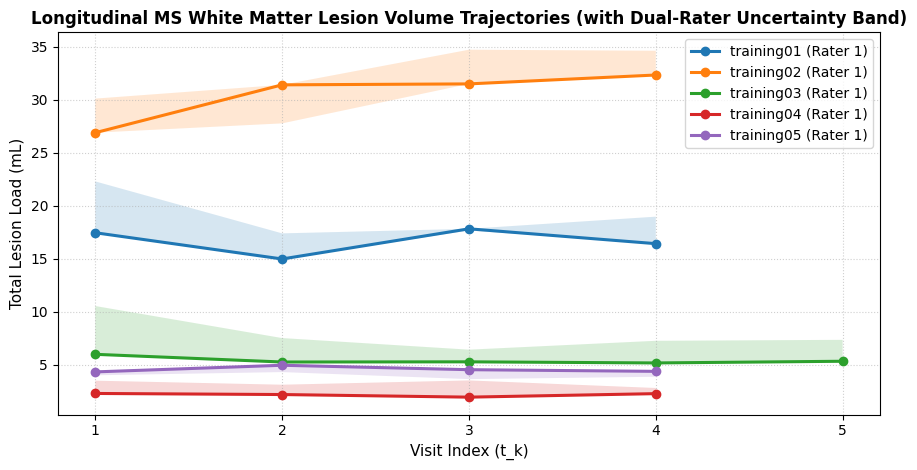

In [5]:
# 4. Cache Labeled Visits in RAM, Compute Human Inter-Rater Ceiling & Plot Lesion Volume Trajectories
import numpy as np
import matplotlib.pyplot as plt
from src.data.transforms import InMemoryVolumeCache
from src.engine.evaluator import compute_binary_dice

cache = InMemoryVolumeCache(modalities=cfg['data']['modalities'], target_rater=cfg['data']['target_rater'], enabled=True)
labeled_pids = sorted([pid for pid, v in patient_visits.items() if v[0].is_labeled])

inter_rater_dices = []
fig, ax = plt.subplots(figsize=(9, 4.8))

for pid in labeled_pids:
    visits = patient_visits[pid]
    timepoints = []
    vols_m1_ml = []
    vols_m2_ml = []
    for v in visits:
        d = cache.get_visit_data(v)
        m1 = d['mask1'][0]
        m2 = d.get('mask2', d['mask1'])[0]
        dice_12 = compute_binary_dice(m1, m2)
        inter_rater_dices.append(dice_12)
        timepoints.append(v.visit_idx)
        vols_m1_ml.append(float((m1 > 0.5).sum()) * 0.001)
        vols_m2_ml.append(float((m2 > 0.5).sum()) * 0.001)
    ax.plot(timepoints, vols_m1_ml, marker='o', linewidth=2.2, label=f'{pid} (Rater 1)')
    ax.fill_between(timepoints, np.minimum(vols_m1_ml, vols_m2_ml), np.maximum(vols_m1_ml, vols_m2_ml), alpha=0.18)

mean_inter_rater = float(np.mean(inter_rater_dices))
print(f'Human Expert Inter-Rater Agreement (Mask1 vs Mask2 across {len(inter_rater_dices)} scans): Dice = {mean_inter_rater:.4f} ± {np.std(inter_rater_dices):.4f}')

ax.set_title('Longitudinal MS White Matter Lesion Volume Trajectories (with Dual-Rater Uncertainty Band)', fontsize=12, fontweight='bold')
ax.set_xlabel('Visit Index (t_k)', fontsize=11)
ax.set_ylabel('Total Lesion Load (mL)', fontsize=11)
ax.set_xticks([1, 2, 3, 4, 5])
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

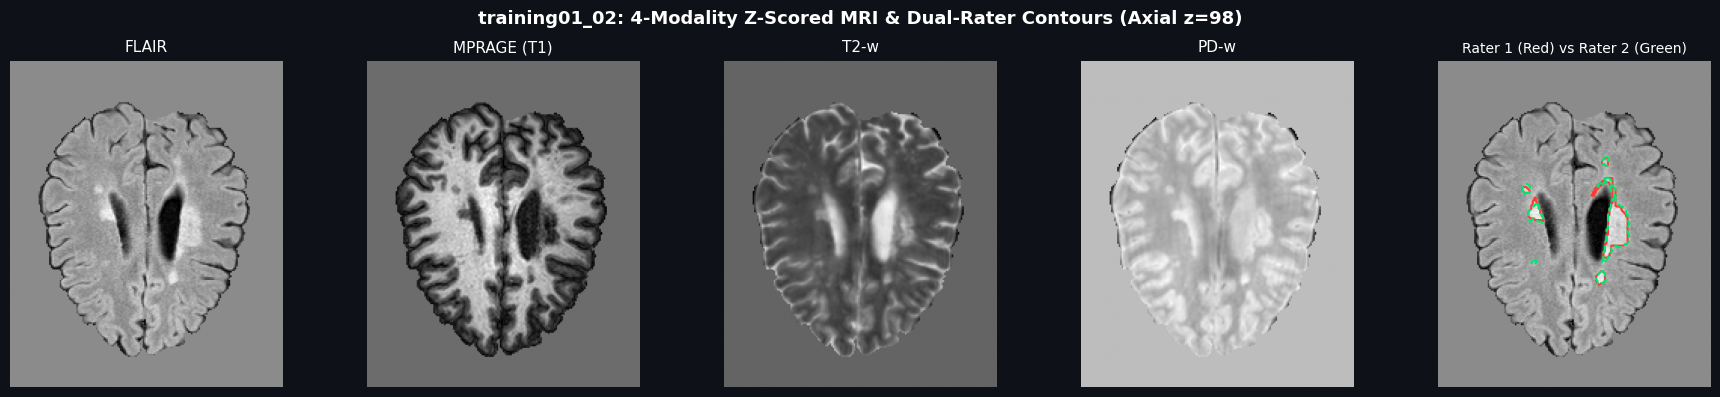

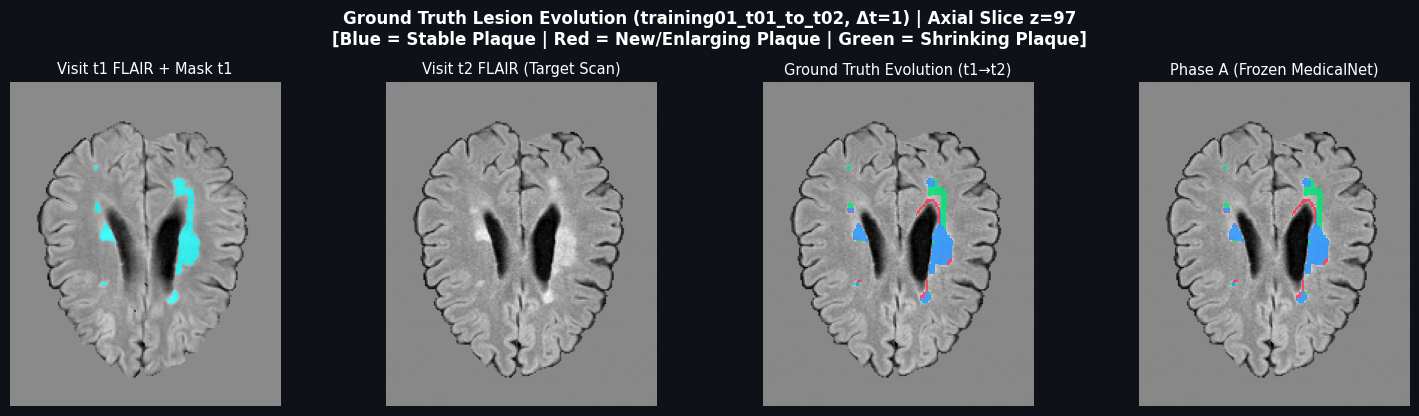

In [6]:
# 5. Visualize Co-Registered 4-Modality MRI & Ground-Truth Longitudinal Lesion Evolution
from src.utils.visualization import plot_four_modalities_and_raters, plot_lesion_evolution_comparison

sample_pid = labeled_pids[0]
sample_pair = patient_pairs[sample_pid][0]  # t1 -> t2
d_t1 = cache.get_visit_data(sample_pair.visit_t1)
d_t2 = cache.get_visit_data(sample_pair.visit_t2)

fig1 = plot_four_modalities_and_raters(
    image_4ch=d_t2['image'],
    mask1=d_t2.get('mask1'),
    mask2=d_t2.get('mask2'),
    title=f'{sample_pair.visit_t2.visit_id}: 4-Modality Z-Scored MRI & Dual-Rater Contours',
)
plt.show()

fig2 = plot_lesion_evolution_comparison(
    flair_t1=d_t1['image'][0],
    flair_t2=d_t2['image'][0],
    gt_mask_t1=d_t1['mask'],
    gt_mask_t2=d_t2['mask'],
    pred_phase_a_t2=d_t2['mask'][0],  # Reference GT illustration
    patient_pair_title=f'Ground Truth Lesion Evolution ({sample_pair.pair_id}, Δt={sample_pair.delta_t_steps})',
)
plt.show()